# Beyond oligodendrocytes: which cell types respond, once spill-over is removed?

analysis/01 compared all mtDSB mice with controls; here responders and non-responders are tested separately in
every cell type. The catch is segmentation spill-over: when OLs lose myelin RNA and microglia switch on Cst7, a
diluted copy of both changes appears in every neighbouring cell type. A linear mixing model on pseudobulk CPM
(`utils/spillover.py`) estimates how much RNA each cell type picks up from each neighbour and how much of each
change that predicts.

* **A.** DE per cell type, responders vs controls and non-responders vs controls (pyDESeq2, `~ age + group`).
* **B.** Contamination fractions between cell types, from source-specific marker genes.
* **C.** Own vs spilled changes.
* **D.** Do the own changes hold within regions (not a by-product of which regions a section contains)?
* **E.** What remains: programmes per cell type.
* **F.** The astrocyte interferon response at single-cell level.

Input: `results/region_time/pseudobulk_counts.csv` + `pseudobulk_meta.csv` (local, gitignored; made by
`scripts/run_region_time_de.py`), `results/cell_table/*.csv.gz`.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
REPO = Path.cwd().resolve().parent; sys.path.insert(0, str(REPO))
from utils import spillover as sp, composition as co
from utils.gene_sets import GENE_SETS
from utils.neighbourhood import local_ol_stress

OUT = REPO / "results" / "celltype_de"; FIG = OUT / "figures"; TAB = OUT / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
sections = pd.read_csv(REPO / "results" / "sample_classifier" / "tables" / "sections_with_responder_calls.csv", index_col=0)
grp = sections["group"]; ctrl = sections.index[grp == "control"]; resp = sections.index[grp == "responder"]
nonr = sections.index[grp == "non-responder"]
order = list(ctrl) + list(nonr) + list(resp)
RT = REPO / "results" / "region_time"
meta = pd.read_csv(RT / "pseudobulk_meta.csv", index_col=0)
counts = pd.read_csv(RT / "pseudobulk_counts.csv", index_col=0)
meta["group"] = meta.sample_id.map(grp)
NEURONS = {"Excitatory Neurons": "Neurons", "GABAergic Neurons": "Neurons", "Medium Spiny Neurons": "Neurons"}
print(meta.shape, counts.shape)

INK2, AXIS = "#52514e", "#c3c2b7"
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b8b7b0"
plt.rcParams.update({"axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "axes.titlelocation": "left"})
GROUP_ORDER = ["control", "non-responder", "responder"]
STYLE = {"control": dict(color=BLUE), "non-responder": dict(facecolor="white", edgecolor=ORANGE), "responder": dict(color=ORANGE)}
def save(fig, name, dpi=200):
    fig.savefig(FIG / f"{name}.png", dpi=dpi, bbox_inches="tight"); fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
def save_table(df, name, index=True):
    df.to_csv(TAB / f"{name}.csv", index=index); return df
def dots(ax, values, title, ylab=None, ref=None):
    for gi, g in enumerate(GROUP_ORDER):
        v = values[values.index.map(grp) == g].to_numpy()
        ax.scatter(np.full(len(v), gi) + np.linspace(-0.12, 0.12, len(v)), v, s=46, linewidth=1.4, zorder=3, **STYLE[g])
    if ref is not None: ax.axhline(ref, color=AXIS, lw=0.8)
    ax.set_xticks(range(3), ["ctrl", "non-resp", "resp"]); ax.set_xlim(-0.5, 2.5); ax.set_title(title, fontsize=9)
    if ylab: ax.set_ylabel(ylab)

(1264, 7) (1264, 5101)


## A. DE per cell type

In [2]:
DE_FILE = TAB / "de_by_celltype.csv"
TYPES = [t for t, n in meta[meta.region == "All regions"].groupby("cell_type").size().items() if n == 12]
if not DE_FILE.exists():   # ~5 min; cached
    from pydeseq2.dds import DeseqDataSet
    from pydeseq2.ds import DeseqStats
    warnings.filterwarnings("ignore")
    m = meta[meta.region == "All regions"].assign(age=lambda d: d.age.astype(str))
    out = []
    for ct in TYPES:
        for case in ("responder", "non-responder"):
            g = m[(m.cell_type == ct) & m.group.isin([case, "control"])].copy()
            g["grp"] = np.where(g.group == case, "case", "ctrl")
            X = counts.loc[g.index].round().astype(int); X = X.loc[:, X.sum() > 0]
            dds = DeseqDataSet(counts=X, metadata=g[["age", "grp"]], design="~age+grp", quiet=True); dds.deseq2()
            st = DeseqStats(dds, contrast=["grp", "case", "ctrl"], quiet=True); st.summary()
            out.append(st.results_df.rename_axis("gene").reset_index().assign(cell_type=ct, case=case))
    pd.concat(out).to_csv(DE_FILE, index=False)
de = pd.read_csv(DE_FILE)
SIG = lambda d: d[(d.padj < 0.05) & (d.log2FoldChange.abs() > 0.5) & (d.baseMean > 20)]
n_sig = SIG(de).groupby(["cell_type", "case"]).size().unstack(fill_value=0).reindex(TYPES, fill_value=0)
display(n_sig.sort_values("responder", ascending=False))

case,non-responder,responder
cell_type,,
Microglia,0,152
Neural Stem Cells,0,133
Endothelial Cells,4,59
Astrocytes,3,45
Oligodendrocytes,1,43
Neurons,1,38
Immature Oligodendrocytes I,0,9
DA-Oligodendrocytes,0,8
GABAergic Neurons,0,8


**A.** Non-responders differ from controls in essentially no cell type (0-4 genes), so induction failure is
complete across the tissue, not only in OLs. Responders differ in every major type, most in microglia, neural stem
cells, endothelial cells and astrocytes. A list like this is the starting point, not the result: many of the hits
are other cell types' RNA, as below.

## B. How much RNA does each cell type pick up from its neighbours?

Oligodendrocytes      43
Microglia            133
Astrocytes            48
Endothelial Cells    126
Neurons                5
Name: n markers, dtype: int64

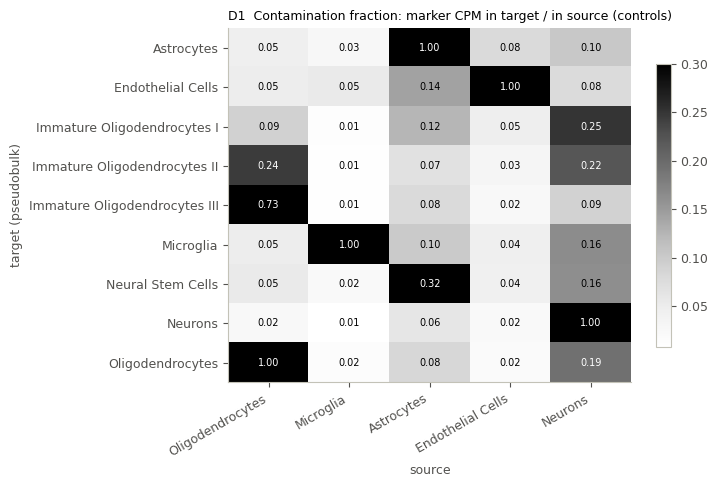

In [3]:
SOURCES = ["Oligodendrocytes", "Microglia", "Astrocytes", "Endothelial Cells", "Neurons"]
m = meta[meta.region == "All regions"].assign(ct=lambda d: d.cell_type.replace({"DA-Oligodendrocytes": "Oligodendrocytes", **NEURONS}))
X = counts.loc[m.index].groupby([m.ct, m.sample_id]).sum()
cpm = X.div(X.sum(1), axis=0) * 1e6
age = sections["age"]
def group_mean(cp, g):
    # mean within each slide (age), then average the two slides, so the 2:1 age split of responders does not bias it
    return sum(cp.loc[(slice(None), [s for s in grp.index if grp[s] == g and age[s] == a]), :].groupby(level=0).mean() for a in (21, 60)) / 2
C_ctrl = group_mean(cpm, "control")
markers = sp.source_markers(C_ctrl, SOURCES)
alpha = sp.contamination(C_ctrl, markers)
save_table(alpha.round(4), "contamination_alpha")
save_table(pd.Series({s: ", ".join(g) for s, g in markers.items()}, name="markers").to_frame(), "source_markers")
fig, ax = plt.subplots(figsize=(6.5, 4.6))
show = alpha.drop(index=[t for t in alpha.index if t in SOURCES and False])
im = ax.imshow(show, cmap="Greys", vmax=0.3, aspect="auto")
for i in range(show.shape[0]):
    for j in range(show.shape[1]):
        ax.text(j, i, f"{show.iat[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w" if show.iat[i, j] > 0.18 else "k")
ax.set_xticks(range(show.shape[1]), show.columns, rotation=30, ha="right"); ax.set_yticks(range(show.shape[0]), show.index)
ax.set_xlabel("source"); ax.set_ylabel("target (pseudobulk)")
ax.set_title("D1  Contamination fraction: marker CPM in target / in source (controls)", fontsize=9)
fig.colorbar(im, ax=ax, shrink=0.8); save(fig, "D1_contamination")
display(pd.Series({s: len(g) for s, g in markers.items()}, name="n markers"))

**B.** Each pseudobulk carries roughly 2-5 % of the OL, microglial and endothelial signal of other cell types and
6-14 % of the astrocytic signal (astrocyte processes are everywhere; 32 % in NSCs, which are astrocyte-like); immature OL II/III are mostly OL-like (alpha 0.25-0.73: these clusters are partly mature OLs, not
contamination, so their "spill" estimate is an upper bound). The neuronal source has few clean markers
(5 genes), so its column is the least reliable.

## C. Own vs spilled changes

call,own,spill-over
cell_type,,
Microglia,135,17
Neural Stem Cells,133,0
Endothelial Cells,46,13
Astrocytes,32,13
Oligodendrocytes,33,10
Neurons,12,26
Immature Oligodendrocytes I,1,8
GABAergic Neurons,2,6
DA-Oligodendrocytes,7,1


main_source,Astrocytes,Endothelial Cells,Microglia,Neurons,Oligodendrocytes
cell_type,,,,,
Astrocytes,0,1,6,0,6
DA-Oligodendrocytes,0,0,1,0,0
Endothelial Cells,4,0,1,0,8
Excitatory Neurons,0,0,0,0,2
GABAergic Neurons,2,0,0,0,4
Immature Oligodendrocytes I,3,0,0,0,5
Immature Oligodendrocytes II,0,0,0,0,1
Immature Oligodendrocytes III,0,0,0,0,2
Medium Spiny Neurons,1,0,0,0,3


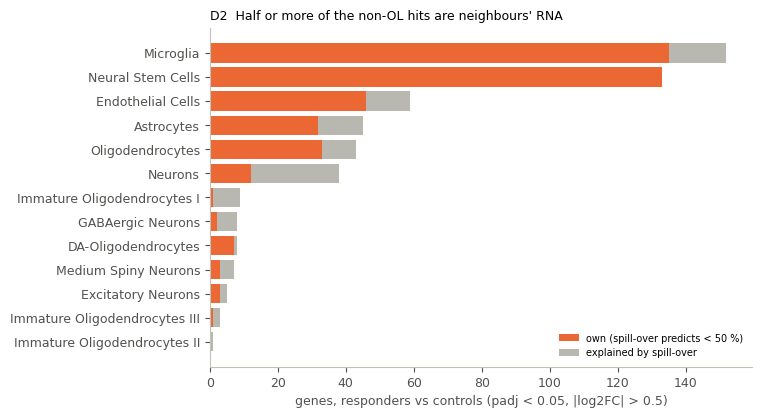

In [4]:
C_resp = group_mean(cpm, "responder")
delta = C_resp - C_ctrl
expected = sp.expected_spill(alpha, delta)
frac = sp.spill_fraction(delta.loc[expected.index], expected)
de_r = SIG(de[de.case == "responder"]).copy()
de_r["ct"] = de_r.cell_type.replace({"DA-Oligodendrocytes": "Oligodendrocytes", **NEURONS})
de_r = de_r[de_r.ct.isin(frac.index)]
de_r["delta_cpm"] = [delta.at[c, g] for c, g in zip(de_r.ct, de_r.gene)]
de_r["expected_spill_cpm"] = [expected.at[c, g] for c, g in zip(de_r.ct, de_r.gene)]
de_r["spill_fraction"] = [frac.at[c, g] for c, g in zip(de_r.ct, de_r.gene)]
de_r["call"] = np.where(de_r.spill_fraction >= 0.5, "spill-over", "own")
top_src = lambda c, g: max((s for s in alpha.columns if s != c), key=lambda s: alpha.at[c, s] * delta.at[s, g] * np.sign(delta.at[c, g]))
de_r["main_source"] = [top_src(c, g) if f >= 0.5 else "" for c, g, f in zip(de_r.ct, de_r.gene, de_r.spill_fraction)]
nc = de_r.groupby(["cell_type", "call"]).size().unstack(fill_value=0).reindex(columns=["own", "spill-over"], fill_value=0)
nc = nc.loc[nc.sum(1).sort_values().index]
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.barh(nc.index, nc["own"], color=ORANGE, label="own (spill-over predicts < 50 %)")
ax.barh(nc.index, nc["spill-over"], left=nc["own"], color=GREY, label="explained by spill-over")
ax.set_xlabel("genes, responders vs controls (padj < 0.05, |log2FC| > 0.5)"); ax.legend(frameon=False, fontsize=7, loc="lower right")
ax.set_title("D2  Half or more of the non-OL hits are neighbours' RNA", fontsize=9); save(fig, "D2_own_vs_spill")
display(nc[::-1])
display(de_r[de_r.call == "spill-over"].groupby(["cell_type", "main_source"]).size().unstack(fill_value=0))

**C.** In neurons and the immature OL clusters most hits are explained by spill-over (myelin genes "down" from OLs,
Cst7/Ccl3 "up" from microglia, Gfap/C4b from astrocytes). Microglia, astrocytes and endothelial cells keep a
substantial set of own changes; OLs keep the ISR genes (Atf5, Trib3, Cdkn1a), which spill-over cannot explain
because no neighbour changes them as much.

## D. Do the own changes hold within regions?

In [5]:
REG = ["Thalamus", "Fiber tracts", "Hypothalamus", "Striatum", "Cortex", "Hippocampus", "Ventricular system"]
mr = meta[meta.region.isin(REG)].assign(ct=lambda d: d.cell_type.replace({"DA-Oligodendrocytes": "Oligodendrocytes", **NEURONS}))
Xr = counts.loc[mr.index].groupby([mr.ct, mr.region, mr.sample_id]).sum()
cpm_r = Xr.div(Xr.sum(1), axis=0) * 1e6
def region_lfc(ct, region, genes):
    try:
        d = cpm_r.loc[(ct, region)]
    except KeyError:
        return pd.Series(np.nan, index=genes)
    if len(d) < 12: return pd.Series(np.nan, index=genes)
    sub = lambda g: sum(d.loc[[s for s in d.index if grp[s] == g and age[s] == a], genes].mean() for a in (21, 60)) / 2
    return np.log2((sub("responder") + 5) / (sub("control") + 5))
own = de_r[de_r.call == "own"].copy()
rl = []
for ct, g in own.groupby("ct"):
    genes = g.gene.unique().tolist()
    rl.append(pd.DataFrame({r: region_lfc(ct, r, genes) for r in REG}).assign(ct=ct))
rl = pd.concat(rl).rename_axis("gene").reset_index()
own = own.merge(rl, on=["ct", "gene"], how="left")
sgn = np.sign(own.log2FoldChange)
same = np.column_stack([(np.sign(own[r]) == sgn) & (own[r].abs() > 0.3) for r in REG])
tested = own[REG].notna().sum(1)
own["n_regions_tested"] = tested; own["n_regions_same"] = same.sum(1)
own["consistent"] = np.where(tested >= 2, own.n_regions_same >= 2, np.nan)   # NaN: cell type in < 2 regions in all 12 sections
save_table(own.sort_values(["cell_type", "padj"]).round(4), "own_changes_with_region_lfc", index=False)
cons = own.groupby("cell_type").agg(own=("gene", "size"), regions_tested=("n_regions_tested", "max"), consistent=("consistent", "sum"))
display(cons.sort_values("own", ascending=False))
nsc = own[own.cell_type == "Neural Stem Cells"].sort_values("padj")
for d, lab in ((nsc.log2FoldChange < 0, "down"), (nsc.log2FoldChange > 0, "up")):
    print(f"NSC {lab}:", ", ".join(f"{g}({l:+.1f}; ventricle {v:+.1f})" for g, l, v in nsc[d].head(18)[["gene", "log2FoldChange", "Ventricular system"]].to_numpy()))

,own,regions_tested,consistent
cell_type,,,
Microglia,135,6,135.0
Neural Stem Cells,133,1,0.0
Endothelial Cells,46,7,25.0
Oligodendrocytes,33,7,31.0
Astrocytes,32,7,32.0
Neurons,12,7,10.0
DA-Oligodendrocytes,7,7,2.0
Excitatory Neurons,3,7,3.0
Medium Spiny Neurons,3,7,2.0


NSC down: Gpc3(-6.1; ventricle -5.2), Tbx3(-4.2; ventricle -5.1), Tiparp(-1.6; ventricle -1.8), Col23a1(-5.4; ventricle -7.2), Rara(-2.4; ventricle -2.4), Rragd(-1.1; ventricle -1.1), Sdc2(-1.6; ventricle -1.6), Hes1(-2.7; ventricle -2.5), Laptm4b(-0.9; ventricle -1.1), Cfap69(-1.6; ventricle -1.6), Jam2(-1.1; ventricle -1.1), Fzd5(-2.3; ventricle -2.1), Fgf2(-2.6; ventricle -2.2), Ttyh1(-1.1; ventricle -1.1), Alpl(-2.3; ventricle -2.1), Slc6a11(-1.9; ventricle -2.3), Frzb(-6.2; ventricle -6.9), Mlec(-1.1; ventricle -1.0)
NSC up: Hist2h2bb(+1.1; ventricle +1.0), Sgo2a(+1.5; ventricle +1.4), Knstrn(+1.6; ventricle +1.3), Knl1(+1.5; ventricle +1.1), Ccna2(+1.1; ventricle +0.9), Foxg1(+1.2; ventricle +0.9), Racgap1(+1.3; ventricle +1.1), Ephb2(+1.2; ventricle +1.2), Ccnb1(+1.6; ventricle +1.0), Erbb4(+0.9; ventricle +1.1), Elavl2(+1.1; ventricle +0.9), Cttnbp2(+0.7; ventricle +0.8), Top2a(+1.4; ventricle +1.0), Cenpa(+1.3; ventricle +1.1), Sema6c(+1.1; ventricle +1.3), Cenpf(+1.4; ventric

**D.** For cell types present in several regions of every section, each own change is required to reappear (same
sign, |log2FC| > 0.3) in at least two regions. All microglial, astrocytic and OL own changes pass; about half of the
endothelial ones do (25 / 46), the rest being whole-section composition effects.

**Neural stem cells cannot be checked this way** (they sit only in the ventricular system), and their 133 "changes"
are better read as anatomy. Down in responders are third-ventricle / tanycyte genes (Tbx3, Gpc3, Col23a1, Rara,
Hes1); up are telencephalic and lateral-ventricle neurogenic genes (Foxg1, Elavl2, Erbb4, Sema6c) together with
cell-cycle genes (Ccnb1, Ccna2, Top2a, Cenpf, Knl1). That is what a section capturing more lateral-ventricle wall
(subventricular zone, the proliferative niche) and less third ventricle would look like. (The missing pallidum in
analysis/11 A is a separate issue: analysis/14 shows it was the region map, not the plane.) So the NSC "proliferative
response" in the manuscript (results/paper/7, from the pooled analysis) cannot be separated from which ventricular
wall is in the section; a per-cell test within lateral-ventricle (Foxg1+) NSCs is needed (section G).

## E. What remains

,cell_type,programme,n_genes,genes
0,Microglia,DAM,14,"Ank(+0.9), Axl(+2.2), Cd74(+4.1), Cd9(+1.1), C..."
1,Microglia,HOMEOSTATIC,1,P2ry12(-0.6)
2,Microglia,ASTRO_REACTIVE,3,"Gfap(+1.3), H2-D1(+1.3), Serpina3n(+2.3)"
3,Microglia,MHC1,5,"B2m(+0.5), H2-D1(+1.3), H2-K1(+0.9), Nlrc5(+1...."
4,Microglia,IFN,1,Usp18(+1.4)
5,Microglia,PROLIF,1,Mki67(+1.9)
6,Microglia,OPC,1,Cspg4(+0.8)
7,Microglia,AXON_INJURY,1,Lgals1(+0.7)
8,Astrocytes,MYELIN,1,Mbp(-0.6)
9,Astrocytes,DAM,1,Gpnmb(+0.9)


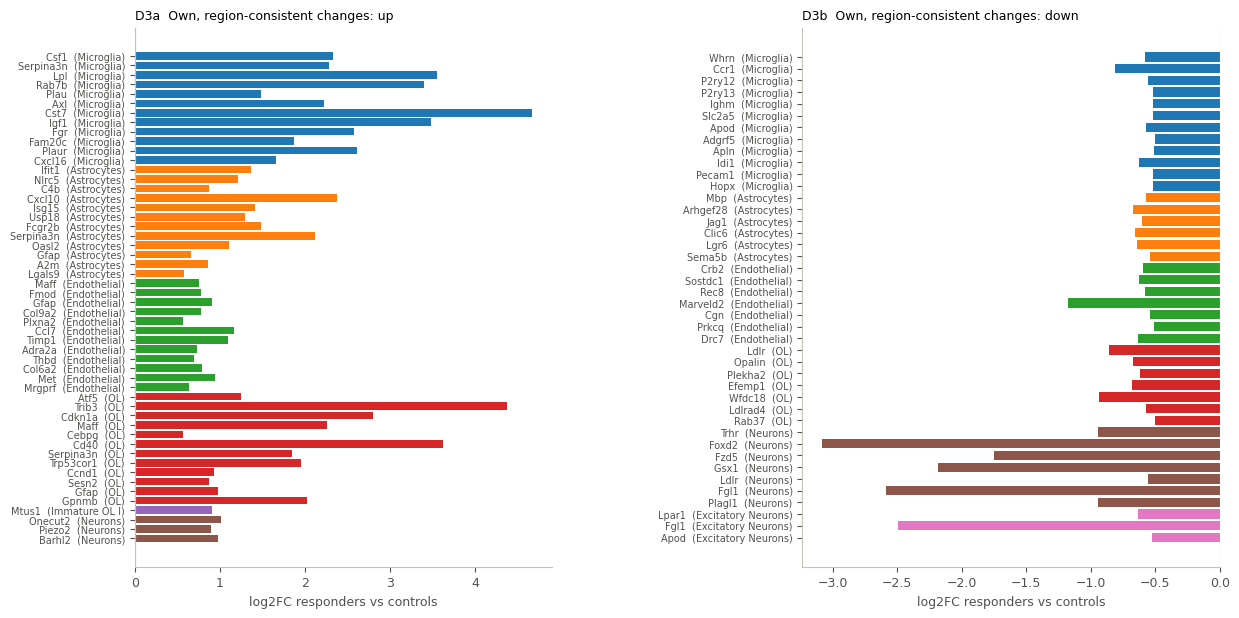

In [6]:
keep = own[own.consistent.fillna(False).astype(bool)]
SHOW = ["Microglia", "Astrocytes", "Endothelial Cells", "Oligodendrocytes", "Immature Oligodendrocytes I", "Neurons", "Excitatory Neurons", "Neural Stem Cells"]
fig, axes = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={"wspace": 0.6})
for ax, direction in zip(axes, ("up", "down")):
    rows = []
    for ct in SHOW:
        k = keep[(keep.cell_type == ct) & ((keep.log2FoldChange > 0) == (direction == "up"))].sort_values("padj").head(12)
        rows += [(ct, g, l) for g, l in zip(k.gene, k.log2FoldChange)]
    if not rows: ax.axis("off"); continue
    t = pd.DataFrame(rows, columns=["ct", "gene", "lfc"])
    y = np.arange(len(t))
    ax.barh(y, t.lfc, color=[plt.get_cmap("tab10")(SHOW.index(c)) for c in t.ct])
    ax.set_yticks(y, [f"{g}  ({c.replace('Oligodendrocytes', 'OL').replace(' Cells', '')})" for g, c in zip(t.gene, t.ct)], fontsize=7)
    ax.invert_yaxis(); ax.axvline(0, color=AXIS, lw=0.8); ax.set_xlabel("log2FC responders vs controls")
    ax.set_title(f"D3{'ab'[direction == 'down']}  Own, region-consistent changes: {direction}", fontsize=9)
save(fig, "D3_surviving_genes")
# gene-set view: which prespecified programmes carry the own changes?
prog = []
for ct in SHOW:
    k = keep[keep.cell_type == ct]
    for s, genes in GENE_SETS.items():
        hit = k[k.gene.isin(genes)]
        if len(hit): prog.append({"cell_type": ct, "programme": s, "n_genes": len(hit), "genes": ", ".join(f"{g}({l:+.1f})" for g, l in zip(hit.gene, hit.log2FoldChange))})
prog = save_table(pd.DataFrame(prog), "programmes_in_own_changes", index=False)
display(prog)

**E.** After both filters the non-OL response is compact:

* **Microglia**: the DAM / lipid-handling programme (Cst7, Lpl, Igf1, Axl, Cd9, Itgax, Gpnmb) plus growth factors
  and chemokines (Csf1, Cxcl16, Plau/Plaur); homeostatic genes modestly down. This is the largest own response
  outside OLs and fits the microgliosis of analysis/11.
* **Astrocytes**: reactive genes (Serpina3n, C4b, Gfap, A2m) and a **type-I interferon / MHC-I programme**
  (Isg15, Ifit1/3, Usp18, Oasl2, Cxcl10, Nlrc5), section F.
* **Endothelial cells**: a smaller interferon / activation response.
* **Neurons, immature OLs**: little that survives. The surviving neuronal "down" genes (Foxd2, Gsx1, Fzd5, Fgl1)
  are markers of particular nuclei, i.e. again section plane rather than a neuronal response. NSCs: not testable
  here (D, G).

## F. The astrocyte interferon response at single-cell level

,r_microglia_50um,r_ol_isr_50um,group
RB4620,-0.008,0.009,control
RB4658,-0.030,0.001,control
RB4676,-0.018,-0.014,control
RB4282,-0.006,0.003,control
RB4350,-0.007,0.004,control
RB4498,-0.009,-0.014,control
RB4630,-0.030,-0.007,non-responder
RB4653,0.025,-0.001,non-responder
RB4403,-0.009,0.024,non-responder
RB4627,-0.006,-0.006,responder


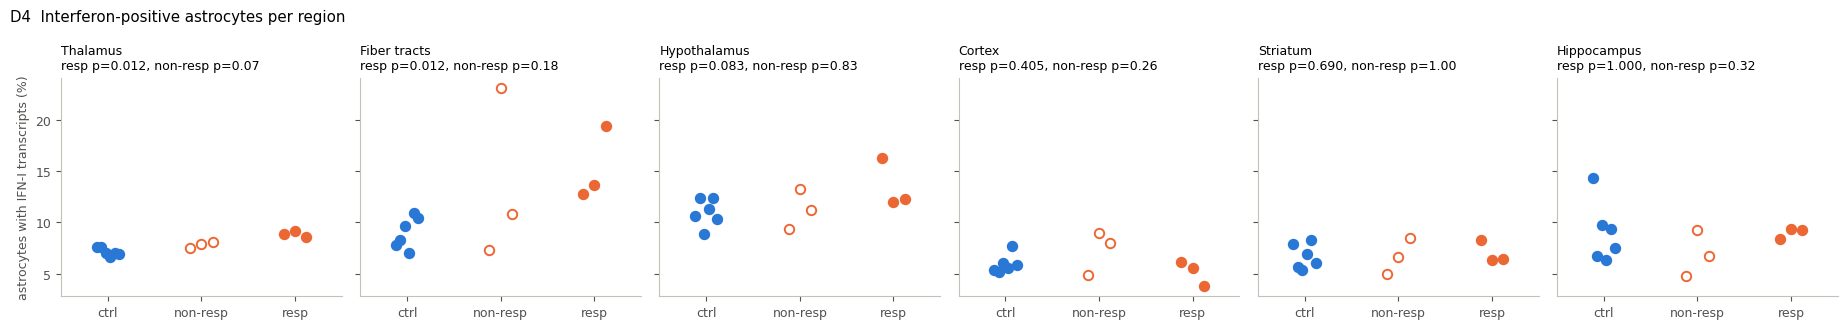

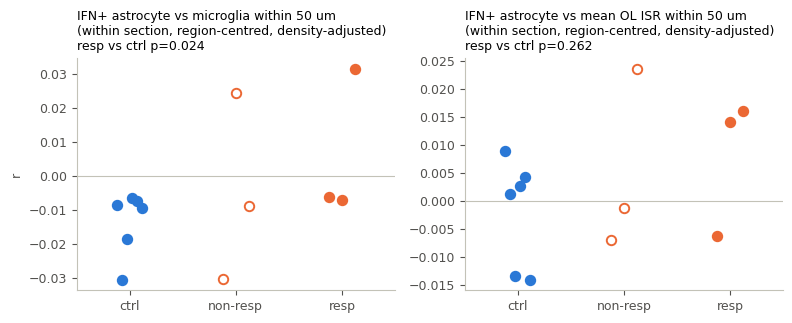

In [7]:
cells = pd.read_csv(REPO / "results" / "cell_table" / "cells.csv.gz", usecols=["cell_id", "sample_id", "x_centroid", "y_centroid"])
gs = pd.read_csv(REPO / "results" / "cell_table" / "cell_gene_scores.csv.gz", usecols=["cell_id", "sample_id", "cell_type", "region", "ISR", "IFN", "MHC1", "ASTRO_REACTIVE"])
cs = gs.merge(cells, on=["cell_id", "sample_id"])
ast = cs[cs.cell_type == "Astrocytes"]
REGF = ["Thalamus", "Fiber tracts", "Hypothalamus", "Cortex", "Striatum", "Hippocampus"]
ifn = ast.groupby(["sample_id", "region"]).IFN.apply(lambda v: (v > 0).mean() * 100).unstack().loc[order, REGF]
save_table(ifn.round(2), "astro_ifn_positive_pct_by_region")
fig, axes = plt.subplots(1, len(REGF), figsize=(3.1 * len(REGF), 3.3), sharey=True)
for ax, r in zip(axes, REGF):
    _, pr = co.exact_perm(ifn[r], resp, ctrl); _, pn = co.exact_perm(ifn[r], nonr, ctrl)
    dots(ax, ifn[r], f"{r}\nresp p={pr:.3f}, non-resp p={pn:.2f}", ylab="astrocytes with IFN-I transcripts (%)" if r == REGF[0] else None)
fig.suptitle("D4  Interferon-positive astrocytes per region", x=0.01, ha="left"); fig.tight_layout(); save(fig, "D4_astro_ifn_by_region")

# within section: do IFN-positive astrocytes sit near stressed OLs or near microglia?
parts = []
for sid, sec in cs.groupby("sample_id"):
    a = sec[sec.cell_type == "Astrocytes"]
    parts.append(a.assign(n_mg=co.neighbour_counts(a, sec[sec.cell_type == "Microglia"]), n_all=co.neighbour_counts(a, sec)))
ast = pd.concat(parts)
lo = local_ol_stress(cs, ["Astrocytes"], radius=50, score="ISR").set_index(["sample_id", "cell_id"])["ol_stress"]
ast = ast.join(lo, on=["sample_id", "cell_id"])
ast["ifn_pos"] = (ast.IFN > 0).astype(float)
def centred_r(d, xcol):
    d = d.dropna(subset=[xcol])
    c = d[[xcol, "ifn_pos", "n_all"]] - d.groupby("region")[[xcol, "ifn_pos", "n_all"]].transform("mean")
    # partial out local cell density
    rx = c[xcol] - np.polyfit(c.n_all, c[xcol], 1)[0] * c.n_all
    return np.corrcoef(rx, c.ifn_pos)[0, 1]
coup = pd.DataFrame({sid: {"r_microglia_50um": centred_r(d, "n_mg"), "r_ol_isr_50um": centred_r(d, "ol_stress")}
                     for sid, d in ast.groupby("sample_id")}).T.loc[order]
save_table(coup.round(4), "astro_ifn_coupling")
fig, axes = plt.subplots(1, 2, figsize=(8, 3.3))
for ax, col, lab in zip(axes, coup.columns, ["microglia within 50 um", "mean OL ISR within 50 um"]):
    _, pr = co.exact_perm(coup[col], resp, ctrl)
    dots(ax, coup[col], f"IFN+ astrocyte vs {lab}\n(within section, region-centred, density-adjusted)\nresp vs ctrl p={pr:.3f}", ylab="r" if ax is axes[0] else None, ref=0)
fig.tight_layout(); save(fig, "D5_astro_ifn_coupling")
display(coup.round(3).assign(group=grp))

**F.** Astrocytes carrying any type-I interferon transcript are more frequent in responder fibre tracts (12.8-19.4 %
vs 7.1-10.9 % in controls) and thalamus (8.6-9.2 % vs 6.6-7.7 %), but the non-responder RB4653 has the highest
fibre-tract value of all (23 %), so per region this is not a clean responder signal. Within sections, IFN-positive
astrocytes are no closer to microglia or to stressed OLs than other astrocytes (r within +/-0.03 everywhere). So the
astrocyte interferon programme is real in pseudobulk (and not spill-over: no neighbour changes these genes as much)
but small, patchy and not organised around the OL lesion, unlike the IFN-gamma-driven response in EAE (analysis/10).

## G. Neural stem cells per cell: is there more proliferation within the same niche?

,n,lateral_ventricle,third_ventricle,prolif_all,prolif_lateral_ventricle,n_lateral_ventricle,group,age
sample_id,,,,,,,,
RB4620,354,0.497,0.003,0.311,0.438,176,control,21
RB4658,320,0.459,0.003,0.431,0.626,147,control,21
RB4676,395,0.605,0.008,0.506,0.657,239,control,21
RB4282,440,0.207,0.114,0.252,0.516,91,control,60
RB4350,458,0.168,0.140,0.295,0.610,77,control,60
RB4498,457,0.249,0.140,0.333,0.570,114,control,60
RB4630,279,0.505,0.004,0.548,0.745,141,non-responder,21
RB4653,1041,0.252,0.257,0.245,0.359,262,non-responder,21
RB4403,491,0.473,0.004,0.422,0.659,232,non-responder,60


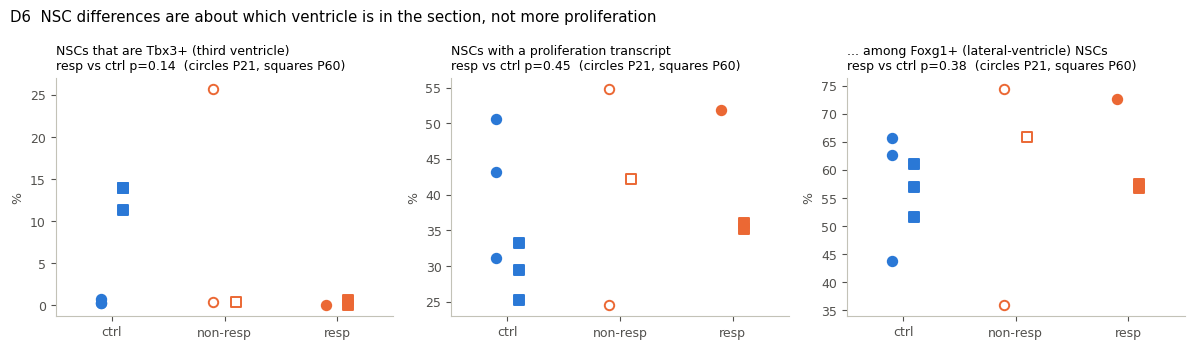

In [8]:
nc = pd.read_csv(REPO / "results" / "cell_table" / "nsc_ol_lineage_counts.csv.gz")   # scripts/export_cell_counts.py
nsc = nc[nc.cell_type == "Neural Stem Cells"].copy()
PRO = ["Mki67", "Top2a", "Ccnb1", "Cenpf", "Pcna", "Mcm2", "Ccna2"]
nsc["prolif"] = nsc[PRO].sum(1) > 0
nsc["lv"] = nsc.Foxg1 > 0            # telencephalic: lateral-ventricle wall
nsc["v3"] = nsc.Tbx3 > 0             # third-ventricle / tanycyte
t = nsc.groupby("sample_id").agg(n=("prolif", "size"), lateral_ventricle=("lv", "mean"), third_ventricle=("v3", "mean"),
                                 prolif_all=("prolif", "mean")).loc[order]
t["prolif_lateral_ventricle"] = nsc[nsc.lv].groupby("sample_id").prolif.mean()
t["n_lateral_ventricle"] = nsc[nsc.lv].groupby("sample_id").size()
save_table(t.round(4), "nsc_niche_and_proliferation")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col, lab in zip(axes, ["third_ventricle", "prolif_all", "prolif_lateral_ventricle"],
                        ["NSCs that are Tbx3+ (third ventricle)", "NSCs with a proliferation transcript", "... among Foxg1+ (lateral-ventricle) NSCs"]):
    for gi, g in enumerate(GROUP_ORDER):
        for a, mk in ((21, "o"), (60, "s")):
            ss = [x for x in order if grp[x] == g and age[x] == a]
            ax.scatter(np.full(len(ss), gi) + (-0.1 if a == 21 else 0.1), 100 * t.loc[ss, col], marker=mk, s=46, linewidth=1.4, zorder=3, **STYLE[g])
    _, pr = co.exact_perm(t[col], resp, ctrl)
    ax.set_xticks(range(3), ["ctrl", "non-resp", "resp"]); ax.set_xlim(-0.5, 2.5); ax.set_ylabel("%")
    ax.set_title(f"{lab}\nresp vs ctrl p={pr:.2f}  (circles P21, squares P60)", fontsize=9)
fig.suptitle("D6  NSC differences are about which ventricle is in the section, not more proliferation", x=0.01, ha="left")
fig.tight_layout(); save(fig, "D6_nsc_niche")
display(t.round(3).assign(group=grp, age=age))

**G.** Per cell, the plane difference is plain: at P60, 11-14 % of control NSCs are Tbx3+ third-ventricle cells
against 0-0.7 % in both P60 responders (P21 sections have almost none, except the non-responder RB4653 at 26 %). The share of NSCs with a
proliferation transcript does not differ (p = 0.45), and within lateral-ventricle (Foxg1+) NSCs responders sit inside
the control range of their age (P60: 57-58 % vs 52-61 %; P21: 73 % vs 44-66 %; p = 0.38). So there is **no evidence
for an NSC proliferative response**; the pseudobulk signal comes from sections holding different ventricular walls.
The manuscript's NSC point (results/paper/7) should be dropped or rephrased.

## Summary

* **Non-responders**: no change in any cell type; induction failed tissue-wide.
* **Spill-over matters**: most neuronal and immature-OL hits are neighbours' RNA (myelin genes from OLs, Cst7/Ccl3
  from microglia, Gfap/C4b from astrocytes). Use `utils/spillover.py` before reading any non-OL change.
* **Own responses outside OLs**: microglia (DAM, lipid handling, Csf1/Igf1 growth factors, MHC), astrocytes (reactive
  genes plus a small, patchy type-I interferon programme not organised around stressed OLs), endothelial cells
  (smaller, partly composition).
* **No NSC response**: the NSC differences track which ventricle the section holds.